# PPO-only dynamic pricing pipeline (linear Gaussian policy, NumPy PPO)
Each cell defines its stage **and runs it**, so the result of that stage prints right under the cell.
All graphs are shown inline in Colab (nothing is saved as an image file).

Scope: can PPO learn a pricing rule from CONTINUOUS state features? No Q-learning, no ablation, no significance tests.

**Run the cells top to bottom.**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## STAGE 0: CONFIG

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CSV_PATH = "/content/drive/MyDrive/retail_price.csv"   # <- your file
COST_FRAC = 0.60                # unit cost = 60% of product's training-average price (disclose!)
GUARD = 0.20                    # price must stay within +/-20% of average price (disclose!)
MAX_STEP = 0.10                 # action a in [-1,1] -> +/-10% price change
LAMBDA = 1.0                    # stability penalty weight (disclose: arbitrary)
TRAIN_FRAC = 0.80
SEEDS = [0,1,2,3,4]                     # 5 PPO run to keep it simple
N_UPDATES = 80                  # PPO updates (smaller run for beginners)
EPISODES_PER_UPDATE = 8         # episodes sampled per update
GAMMA, LAM, CLIP_EPS = 0.95, 0.95, 0.2
LR_POLICY, LR_VALUE, EPOCHS = 0.02, 0.05, 4
SIGMA_START, SIGMA_END = 0.50, 0.10   # fixed exploration schedule (no entropy bonus)
CHANGE_TOL = 0.005              # a "price change" = more than 0.5%
N_FEATURES = 10

print("STAGE 0: Configuration loaded")
print(f"  CSV_PATH            = {CSV_PATH}")
print(f"  Unit cost           = {COST_FRAC:.0%} of average price")
print(f"  Price guardrail     = +/-{GUARD:.0%} of average price")
print(f"  Max price step      = +/-{MAX_STEP:.0%} per month")
print(f"  Stability penalty   = {LAMBDA}")
print(f"  Train/test split    = {TRAIN_FRAC:.0%} / {1-TRAIN_FRAC:.0%}")
print(f"  Seeds               = {SEEDS}")
print(f"  PPO updates         = {N_UPDATES}  ({EPISODES_PER_UPDATE} episodes each)")

STAGE 0: Configuration loaded
  CSV_PATH            = /content/drive/MyDrive/retail_price.csv
  Unit cost           = 60% of average price
  Price guardrail     = +/-20% of average price
  Max price step      = +/-10% per month
  Stability penalty   = 1.0
  Train/test split    = 80% / 20%
  Seeds               = [0, 1, 2, 3, 4]
  PPO updates         = 80  (8 episodes each)


## STAGE 1: LOAD DATA

In [3]:
def load_data(path=CSV_PATH):
    cols = ["product_id", "month_year", "month", "unit_price", "qty",
            "comp_1", "comp_2", "comp_3", "product_score", "holiday",
            "product_category_name"]
    df = pd.read_csv(path)[cols].copy()
    df["month_year"] = pd.to_datetime(df["month_year"], dayfirst=True, errors="coerce")
    df = df.dropna().query("qty > 0 and unit_price > 0")
    return df.sort_values(["product_id", "month_year"]).reset_index(drop=True)


print("STAGE 1: Loading retail data...")
df = load_data()
print(f"Rows after basic cleaning: {len(df)}")
print(f"Products: {df['product_id'].nunique()}")
print(f"Date range: {df['month_year'].min().date()} -> {df['month_year'].max().date()}")
print("\nFirst 5 rows:")
display(df.head(5))

STAGE 1: Loading retail data...
Rows after basic cleaning: 676
Products: 52
Date range: 2017-01-01 -> 2018-08-01

First 5 rows:


,product_id,month_year,month,unit_price,qty,comp_1,comp_2,comp_3,product_score,holiday,product_category_name
0,bed1,2017-05-01,5,45.95,1,89.9,215.000000,45.95,4.0,1,bed_bath_table
1,bed1,2017-06-01,6,45.95,3,89.9,209.000000,45.95,4.0,1,bed_bath_table
2,bed1,2017-07-01,7,45.95,6,89.9,205.000000,45.95,4.0,1,bed_bath_table
3,bed1,2017-08-01,8,45.95,4,89.9,199.509804,45.95,4.0,1,bed_bath_table
4,bed1,2017-09-01,9,45.95,2,89.9,163.398710,45.95,4.0,1,bed_bath_table


## STAGE 2: SPLIT

In [4]:
def split_train_test(df):
    """Each product: first 80% of months = train, rest = test. Needs >=2 months."""
    tr, te = [], []
    for _, g in df.groupby("product_id"):
        k = int(np.floor(len(g) * TRAIN_FRAC))
        if k < 1 or len(g) - k < 1:
            continue
        tr.append(g.iloc[:k]); te.append(g.iloc[k:])
    return pd.concat(tr), pd.concat(te)


print("STAGE 2: Splitting data by time (first 80% train, last 20% test)...")
train, test = split_train_test(df)
if train.empty or test.empty:
    raise ValueError("Train/test split is empty. Check that each product has at least 2 valid months.")
print(f"Training rows: {len(train)}")
print(f"Testing rows:  {len(test)}")
print(f"Train period: {train['month_year'].min().date()} -> {train['month_year'].max().date()}")
print(f"Test period:  {test['month_year'].min().date()} -> {test['month_year'].max().date()}")

STAGE 2: Splitting data by time (first 80% train, last 20% test)...
Training rows: 523
Testing rows:  153
Train period: 2017-01-01 -> 2018-06-01
Test period:  2017-09-01 -> 2018-08-01


## STAGE 3: DEMAND SIMULATOR

STAGE 3: Fitting demand model using TRAINING data only...
Estimated price elasticity: -2.590
Demand model R-squared (train): 0.125
Demand model R-squared (test):  -0.110
Note: PPO learns inside this estimated demand simulator; results depend on its accuracy.


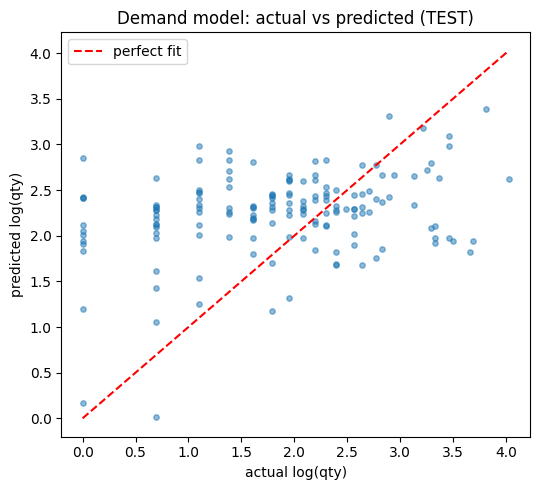

In [5]:
class DemandModel:
    """log(qty) = ridge regression on log(price/avg), competitors, season, score, holiday, category.
    Fitted on TRAIN rows only."""

    def __init__(self, train, alpha=1.0):
        self.avg = train.groupby("product_id")["unit_price"].mean()
        self.cats = sorted(train["product_category_name"].unique())
        X = self._X(train, train["unit_price"].values)
        y = np.log(train["qty"].values)
        A = X.T @ X + alpha * np.eye(X.shape[1])
        A[0, 0] -= alpha                                  # do not penalise intercept
        self.w = np.linalg.solve(A, X.T @ y)
        self.elasticity = self.w[1]
        self.r2_train = self.r2(train)

    def _X(self, d, price):
        avg = d["product_id"].map(self.avg).values
        m = d["month"].values
        cat = np.stack([(d["product_category_name"].values == c).astype(float)
                        for c in self.cats], axis=1)
        base = np.column_stack([
            np.ones(len(d)), np.log(price / avg),
            np.log(d["comp_1"].values / avg), np.log(d["comp_2"].values / avg),
            np.log(d["comp_3"].values / avg),
            np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12),
            d["product_score"].values / 5.0, d["holiday"].values.astype(float)])
        return np.hstack([base, cat])

    def predict_qty(self, d, price):
        return np.exp(self._X(d, price) @ self.w)

    def r2(self, d):
        y = np.log(d["qty"].values)
        p = self._X(d, d["unit_price"].values) @ self.w
        return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()


print("STAGE 3: Fitting demand model using TRAINING data only...")
demand = DemandModel(train)
print(f"Estimated price elasticity: {demand.elasticity:.3f}")
print(f"Demand model R-squared (train): {demand.r2_train:.3f}")
print(f"Demand model R-squared (test):  {demand.r2(test):.3f}")
print("Note: PPO learns inside this estimated demand simulator; results depend on its accuracy.")
if demand.elasticity >= 0:
    print("WARNING: estimated price elasticity is non-negative. Interpret results carefully.")

# Graph: actual vs predicted log-quantity on the test set
y_true = np.log(test["qty"].values)
y_pred = demand._X(test, test["unit_price"].values) @ demand.w
plt.figure(figsize=(5.5, 5))
plt.scatter(y_true, y_pred, alpha=0.5, s=15)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="perfect fit")
plt.xlabel("actual log(qty)"); plt.ylabel("predicted log(qty)")
plt.title("Demand model: actual vs predicted (TEST)")
plt.legend(); plt.tight_layout(); plt.show()

## STAGE 4: ENVIRONMENT

STAGE 4: Creating the pricing environment...
Products available for PPO training: 52
Products available for testing:      52
Reward scaling value: 408.129
Reward = estimated profit - penalty for changing price too much.


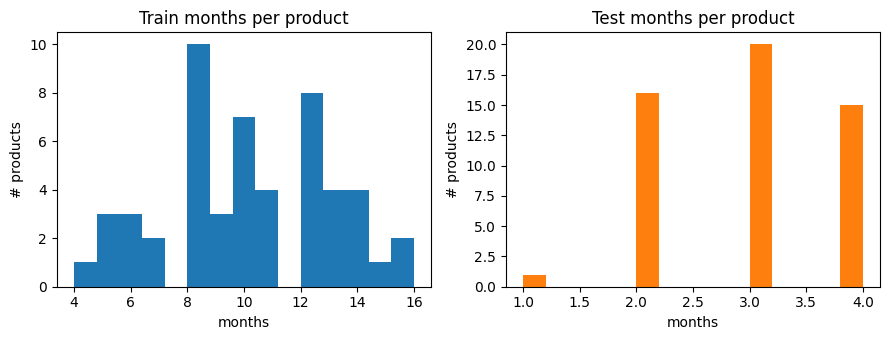

In [6]:
class PricingEnv:
    """One episode = one product's months in order. State = 10 continuous numbers."""

    def __init__(self, df, demand):
        self.demand = demand
        self.products = {}
        for pid, g in df.groupby("product_id"):
            g = g.sort_values("month_year")
            avg = demand.avg[pid]
            c = g[["comp_1", "comp_2", "comp_3"]].values
            c1_prev = np.vstack([c[:1, 0], c[:-1, :1]])[:, 0]
            self.products[pid] = dict(
                rows=g, avg=avg, cost=COST_FRAC * avg, comp=c,
                dc1=np.clip(c[:, 0] / c1_prev - 1, -0.5, 0.5),
                sin=np.sin(2 * np.pi * g["month"].values / 12),
                cos=np.cos(2 * np.pi * g["month"].values / 12),
                score=g["product_score"].values / 5.0,
                hol=g["holiday"].values.astype(float),
                actual_price=g["unit_price"].values)
        self.pids = list(self.products)

    def state(self, p, t, price):
        r = lambda x: float(np.clip(x, 0.5, 2.0))
        return np.array([1.0, r(price / p["avg"]),
                         r(price / p["comp"][t, 0]), r(price / p["comp"][t, 1]),
                         r(price / p["comp"][t, 2]),
                         p["dc1"][t], p["sin"][t], p["cos"][t], p["score"][t], p["hol"][t]])

    def env_step(self, p, t, price, a):
        """Shared by every run: guardrails -> demand -> profit -> stability penalty."""
        proposed = price * (1 + MAX_STEP * float(np.clip(a, -1, 1)))
        lo, hi = p["avg"] * (1 - GUARD), p["avg"] * (1 + GUARD)
        new_price = float(np.clip(proposed, lo, hi))
        outside = proposed < lo or proposed > hi            # proposal broke guardrail
        at_bound = new_price in (lo, hi)
        row = p["rows"].iloc[[t]]
        qty = float(self.demand.predict_qty(row, np.array([new_price]))[0])
        revenue = new_price * qty
        profit = (new_price - p["cost"]) * qty              # profit EXCLUDES penalty
        penalty = LAMBDA * abs(new_price - price)
        return new_price, revenue, profit, profit - penalty, outside, at_bound


print("STAGE 4: Creating the pricing environment...")
env_tr, env_te = PricingEnv(train, demand), PricingEnv(test, demand)
print(f"Products available for PPO training: {len(env_tr.pids)}")
print(f"Products available for testing:      {len(env_te.pids)}")

scale = np.mean([
    (p["avg"] - p["cost"]) *
    np.exp(demand._X(p["rows"], np.full(len(p["rows"]), p["avg"])) @ demand.w).mean()
    for p in env_tr.products.values()
])
scale = max(float(scale), 1.0)
print(f"Reward scaling value: {scale:.3f}")
print("Reward = estimated profit - penalty for changing price too much.")

# Graph: how many months each product has in train vs test
lens_tr = [len(p["rows"]) for p in env_tr.products.values()]
lens_te = [len(env_te.products[k]["rows"]) for k in env_te.pids]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].hist(lens_tr, bins=15, color="tab:blue"); ax[0].set_title("Train months per product")
ax[1].hist(lens_te, bins=15, color="tab:orange"); ax[1].set_title("Test months per product")
for a in ax: a.set_xlabel("months"); a.set_ylabel("# products")
plt.tight_layout(); plt.show()

## STAGE 5: PPO (linear Gaussian) — agent definition

In [7]:
class LinearPPO:
    """Policy: a ~ N(tanh(w.x), sigma^2). Value: v = u.x. Clipped-ratio PPO + GAE.
    NOT a neural network: linear policy and linear value function."""

    def __init__(self, seed):
        self.rng = np.random.default_rng(seed)
        self.w = np.zeros(N_FEATURES)
        self.u = np.zeros(N_FEATURES)

    def mean(self, x):
        return np.tanh(x @ self.w)

    def act(self, x, sigma):
        mu = self.mean(x)
        a = mu + sigma * self.rng.standard_normal()
        return a, mu

    @staticmethod
    def logp(a, mu, sigma):
        return -0.5 * ((a - mu) / sigma) ** 2

    def update(self, S, A, R_adv, R_ret, old_logp, sigma):
        for _ in range(EPOCHS):
            mu = np.tanh(S @ self.w)
            ratio = np.exp(self.logp(A, mu, sigma) - old_logp)
            active = ~(((R_adv > 0) & (ratio > 1 + CLIP_EPS)) |
                       ((R_adv < 0) & (ratio < 1 - CLIP_EPS)))
            dlogp = ((A - mu) / sigma ** 2 * (1 - mu ** 2))[:, None] * S
            g = ((R_adv * ratio * active)[:, None] * dlogp).mean(0)
            self.w += LR_POLICY * g                                    # ascent
            v = S @ self.u
            self.u += LR_VALUE * ((R_ret - v)[:, None] * S).mean(0)    # value regression


def rollout(env, agent, pid, sigma, deterministic=False, start_price=None):
    p = env.products[pid]
    price = p["avg"] if start_price is None else start_price
    T = len(p["rows"])
    out = dict(S=[], A=[], R=[], logp=[], profit=[], revenue=[], prices=[],
               outside=0, bound=0, changes=0)
    for t in range(T):
        x = env.state(p, t, price)
        if deterministic:
            mu = agent.mean(x); a = mu
        else:
            a, mu = agent.act(x, sigma)
        new_price, rev, prof, reward, outside, at_bound = env.env_step(p, t, price, a)
        out["S"].append(x); out["A"].append(a); out["logp"].append(agent.logp(a, mu, sigma))
        out["R"].append(reward); out["profit"].append(prof); out["revenue"].append(rev)
        out["prices"].append(new_price)
        out["outside"] += outside; out["bound"] += at_bound
        out["changes"] += abs(new_price / price - 1) > CHANGE_TOL
        price = new_price
    return out


def gae(R, V, gamma=GAMMA, lam=LAM):
    adv, last = np.zeros(len(R)), 0.0
    V = np.append(V, 0.0)
    for t in reversed(range(len(R))):
        delta = R[t] + gamma * V[t + 1] - V[t]
        last = delta + gamma * lam * last
        adv[t] = last
    return adv, adv + V[:-1]


# Sanity check: one untrained rollout (policy weights are all zero)
print("STAGE 5: PPO agent defined. Quick sanity check with an untrained agent...")
_a0 = LinearPPO(seed=0)
_ro = rollout(env_tr, _a0, env_tr.pids[0], sigma=SIGMA_START)
print(f"Product tested:        {env_tr.pids[0]}")
print(f"Episode length:        {len(_ro['R'])} months")
print(f"State vector size:     {_ro['S'][0].shape[0]} (expected {N_FEATURES})")
print(f"Untrained total reward: {sum(_ro['R']):.2f}")
print(f"Untrained total profit: {sum(_ro['profit']):.2f}")

STAGE 5: PPO agent defined. Quick sanity check with an untrained agent...
Product tested:        bed1
Episode length:        12 months
State vector size:     10 (expected 10)
Untrained total reward: 2496.89
Untrained total profit: 2512.37


## STAGE 6: TRAIN

STAGE 6: Training PPO...

Seed 0:
  update   1/80  sigma=0.50  mean scaled reward=1.1016
  update  10/80  sigma=0.45  mean scaled reward=0.8781
  update  20/80  sigma=0.40  mean scaled reward=0.6719
  update  30/80  sigma=0.35  mean scaled reward=0.7673
  update  40/80  sigma=0.30  mean scaled reward=1.2805
  update  50/80  sigma=0.25  mean scaled reward=0.9322
  update  60/80  sigma=0.20  mean scaled reward=1.1008
  update  70/80  sigma=0.15  mean scaled reward=1.0352
  update  80/80  sigma=0.10  mean scaled reward=0.8909
PPO training finished. First reward average: 1.1016
PPO training finished. Last reward average:  0.8909

Seed 1:
  update   1/80  sigma=0.50  mean scaled reward=0.7281
  update  10/80  sigma=0.45  mean scaled reward=1.3426
  update  20/80  sigma=0.40  mean scaled reward=1.0841
  update  30/80  sigma=0.35  mean scaled reward=1.1756
  update  40/80  sigma=0.30  mean scaled reward=0.9262
  update  50/80  sigma=0.25  mean scaled reward=0.8247
  update  60/80  sigma=0.20 

,0,1,2,3,4
bias,0.0410,0.0872,0.1614,-0.1198,0.1458
price/avg,0.0509,0.1022,0.1569,-0.1223,0.1365
price/comp1,0.1605,0.1191,0.1481,-0.0316,0.1414
price/comp2,0.1653,0.1042,0.0809,-0.0722,0.0794
price/comp3,0.1265,0.0610,0.0991,-0.0328,0.1553
d_comp1,-0.0234,-0.0458,-0.0144,0.0222,-0.0087
sin(month),0.1301,0.1291,0.3755,-0.0866,0.0580
cos(month),0.0415,-0.0761,-0.1235,-0.2361,-0.0337
score,0.0292,0.0720,0.1311,-0.0884,0.1225
holiday,0.2467,0.2978,0.0172,-0.3388,0.1621


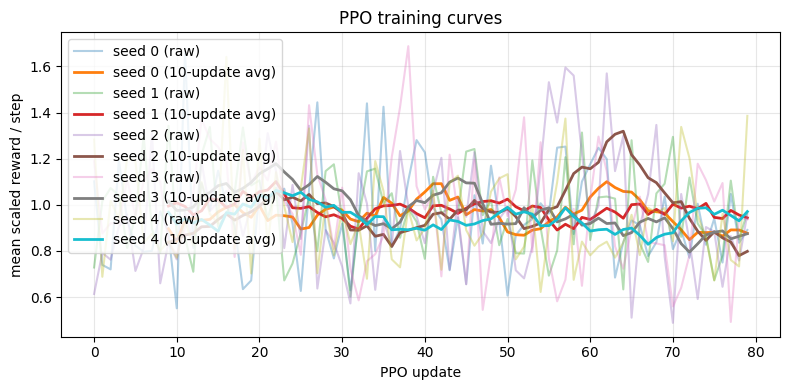

In [12]:
def train_ppo(env_train, seed, reward_scale, verbose=True):
    agent = LinearPPO(seed)
    rng = np.random.default_rng(seed + 1000)
    curve = []
    for it in range(N_UPDATES):
        sigma = SIGMA_START + (SIGMA_END - SIGMA_START) * it / max(N_UPDATES - 1, 1)
        S, A, ADV, RET, LOGP, ep_rewards = [], [], [], [], [], []
        for pid in rng.choice(env_train.pids, EPISODES_PER_UPDATE):
            ro = rollout(env_train, agent, pid, sigma)
            R = np.array(ro["R"]) / reward_scale
            Sx = np.array(ro["S"])
            adv, ret = gae(R, Sx @ agent.u)
            S.append(Sx); A.append(ro["A"]); ADV.append(adv); RET.append(ret)
            LOGP.append(ro["logp"]); ep_rewards.append(R.mean())
        S, A, ADV, RET, LOGP = map(np.concatenate, (S, A, ADV, RET, LOGP))
        ADV = (ADV - ADV.mean()) / (ADV.std() + 1e-8)
        agent.update(S, A, ADV, RET, LOGP, sigma)
        curve.append(np.mean(ep_rewards))
        if verbose and ((it + 1) % 10 == 0 or it == 0):
            print(f"  update {it+1:3d}/{N_UPDATES}  sigma={sigma:.2f}  mean scaled reward={curve[-1]:.4f}")
    return agent, np.array(curve)


print("STAGE 6: Training PPO...")
agents, curves = {}, {}
for seed in SEEDS:
    print(f"\nSeed {seed}:")
    agent, curve = train_ppo(env_tr, seed, scale)
    agents[seed], curves[seed] = agent, curve
    print(f"PPO training finished. First reward average: {curve[0]:.4f}")
    print(f"PPO training finished. Last reward average:  {curve[-1]:.4f}")

feat_names = ["bias", "price/avg", "price/comp1", "price/comp2", "price/comp3",
              "d_comp1", "sin(month)", "cos(month)", "score", "holiday"]
print("\nLearned policy weights (w):")
display(pd.DataFrame({s: a.w for s, a in agents.items()}, index=feat_names).round(4))

# Graph: training curves (raw + smoothed)
plt.figure(figsize=(8, 4))
for s, c in curves.items():
    plt.plot(c, alpha=0.35, label=f"seed {s} (raw)")
    k = min(10, len(c))
    plt.plot(np.arange(k - 1, len(c)), np.convolve(c, np.ones(k) / k, mode="valid"),
             linewidth=2, label=f"seed {s} ({k}-update avg)")
plt.xlabel("PPO update"); plt.ylabel("mean scaled reward / step")
plt.title("PPO training curves"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## STAGE 7: EVALUATE (TEST months)

In [14]:
def evaluate(env_test, agent):
    rows, per_step, per_price = [], {}, {}
    for pid in env_test.pids:
        ro = rollout(env_test, agent, pid, sigma=1.0, deterministic=True)
        T = len(ro["profit"])
        rows.append(dict(product_id=pid, T=T, profit=sum(ro["profit"]),
                         revenue=sum(ro["revenue"]), changes=ro["changes"],
                         outside=ro["outside"], bound=ro["bound"],
                         mean_abs_change=np.mean(np.abs(np.diff(
                             np.r_[env_test.products[pid]["avg"], ro["prices"]])
                             / env_test.products[pid]["avg"]))))
        per_step[pid] = np.array(ro["profit"])
        per_price[pid] = np.array(ro["prices"])
    d = pd.DataFrame(rows)
    return dict(
        total_profit=d.profit.sum(),
        margin=d.profit.sum() / d.revenue.sum(),
        pct_months_price_changed=100 * d.changes.sum() / d["T"].sum(),
        n_proposals_outside_guardrails=int(d.outside.sum()),
        n_steps_at_bound=int(d.bound.sum()),
        mean_abs_price_change=d.mean_abs_change.mean()), per_step, per_price, d


print("STAGE 7: Evaluating the learned PPO policy on TEST months...")
results, steps, prices, per_product = [], {}, {}, {}
for seed in SEEDS:
    m, ps, pp, d = evaluate(env_te, agents[seed])
    m["seed"] = seed
    results.append(m); steps[seed] = ps; prices[seed] = pp; per_product[seed] = d

res = pd.DataFrame(results).set_index("seed")
print("\nTest metrics per seed:")
display(res.round(3))

print("\nWhat the test metrics mean:")
print("- total_profit: total estimated profit on test months")
print("- margin: estimated profit divided by revenue")
print("- pct_months_price_changed: percent of test months where price changed")
print("- n_proposals_outside_guardrails: number of actions that proposed a price outside the allowed range")
print("- n_steps_at_bound: number of final prices at the +/-20% limit")
print("- mean_abs_price_change: average absolute price movement relative to average price")

print("\nSummary across seeds:")
display(res.describe().T.round(3))

STAGE 7: Evaluating the learned PPO policy on TEST months...

Test metrics per seed:


,total_profit,margin,pct_months_price_changed,n_proposals_outside_guardrails,n_steps_at_bound,mean_abs_price_change
seed,,,,,,
0,49739.480,0.470,90.850,42,42,0.062
1,49699.288,0.471,90.196,46,46,0.064
2,49708.110,0.471,90.196,44,44,0.062
3,50223.417,0.320,100.000,9,9,0.050
4,49605.351,0.473,90.196,49,49,0.066



What the test metrics mean:
- total_profit: total estimated profit on test months
- margin: estimated profit divided by revenue
- pct_months_price_changed: percent of test months where price changed
- n_proposals_outside_guardrails: number of actions that proposed a price outside the allowed range
- n_steps_at_bound: number of final prices at the +/-20% limit
- mean_abs_price_change: average absolute price movement relative to average price

Summary across seeds:


,count,mean,std,min,25%,50%,75%,max
total_profit,5.0,49795.129,244.592,49605.351,49699.288,49708.110,49739.480,50223.417
margin,5.0,0.441,0.068,0.320,0.470,0.471,0.471,0.473
pct_months_price_changed,5.0,92.288,4.321,90.196,90.196,90.196,90.850,100.000
n_proposals_outside_guardrails,5.0,38.000,16.416,9.000,42.000,44.000,46.000,49.000
n_steps_at_bound,5.0,38.000,16.416,9.000,42.000,44.000,46.000,49.000
mean_abs_price_change,5.0,0.061,0.006,0.050,0.062,0.062,0.064,0.066


## STAGE 8: PLOTS (shown inline)

STAGE 8: Graphs

1) Mean profit per product at each test month


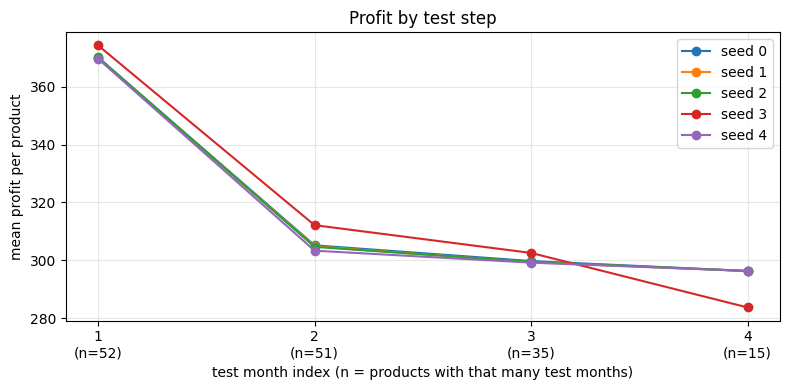


2) PPO price path vs actual price (first few test products)


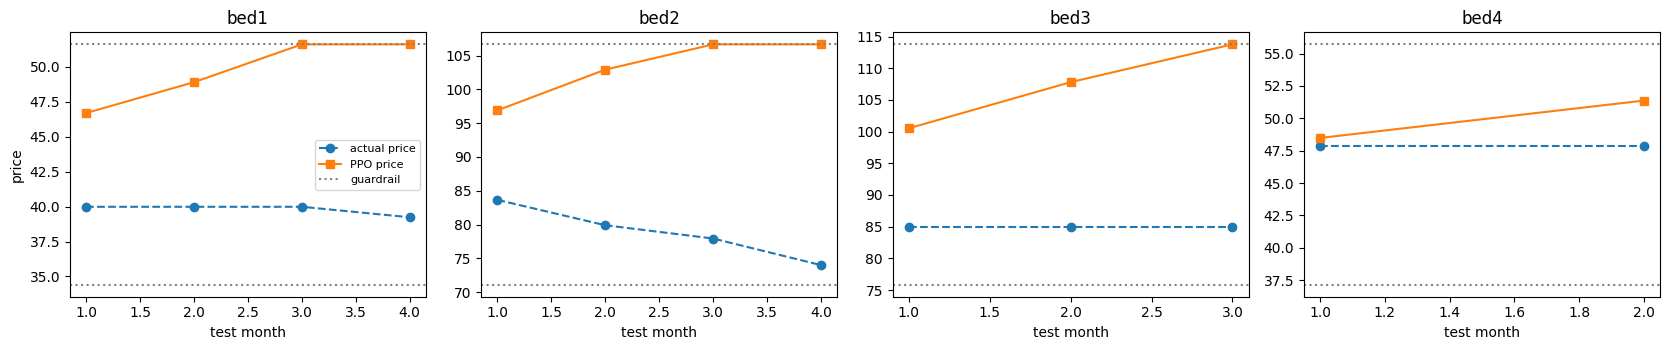


3) Estimated test profit, top products


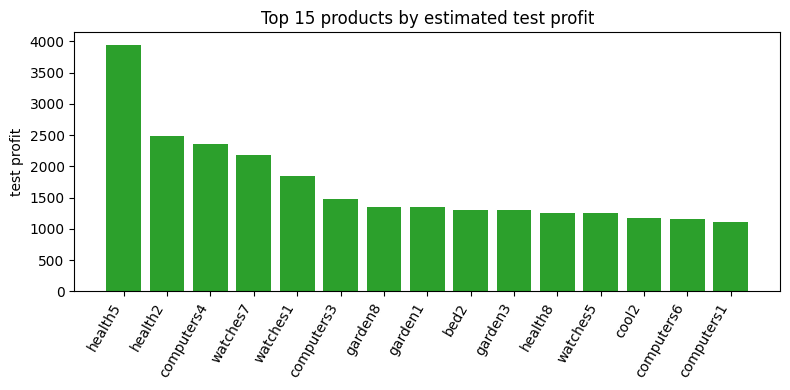

In [15]:
def plot_profit_by_test_step(per_step_by_seed):
    """Per-product AVERAGE profit at each test step, with the product count at each step
    (so the curve never drops just because fewer products reach later steps)."""
    plt.figure(figsize=(8, 4))
    maxT = max(len(v) for ps in per_step_by_seed.values() for v in ps.values())
    for s, ps in per_step_by_seed.items():
        avg = [np.mean([v[t] for v in ps.values() if len(v) > t]) for t in range(maxT)]
        plt.plot(range(1, maxT + 1), avg, marker="o", label=f"seed {s}")
    n_at = [sum(len(v) > t for v in next(iter(per_step_by_seed.values())).values())
            for t in range(maxT)]
    plt.xticks(range(1, maxT + 1), [f"{t+1}\n(n={n})" for t, n in enumerate(n_at)])
    plt.xlabel("test month index (n = products with that many test months)")
    plt.ylabel("mean profit per product")
    plt.title("Profit by test step"); plt.grid(alpha=0.3)
    plt.legend(); plt.tight_layout(); plt.show()


def plot_price_paths(env_test, prices_by_pid, n=4):
    """PPO price vs actual historical price vs allowed band for a few test products."""
    pids = env_test.pids[:n]
    fig, axes = plt.subplots(1, len(pids), figsize=(4.2 * len(pids), 3.6), squeeze=False)
    for ax, pid in zip(axes[0], pids):
        p = env_test.products[pid]
        x = range(1, len(p["rows"]) + 1)
        ax.plot(x, p["actual_price"], "o--", label="actual price")
        ax.plot(x, prices_by_pid[pid], "s-", label="PPO price")
        ax.axhline(p["avg"] * (1 + GUARD), color="gray", ls=":", label="guardrail")
        ax.axhline(p["avg"] * (1 - GUARD), color="gray", ls=":")
        ax.set_title(str(pid)); ax.set_xlabel("test month")
    axes[0][0].set_ylabel("price"); axes[0][0].legend(fontsize=8)
    plt.tight_layout(); plt.show()


def plot_profit_per_product(per_product_df, top=15):
    d = per_product_df.sort_values("profit", ascending=False).head(top)
    plt.figure(figsize=(8, 4))
    plt.bar(d["product_id"].astype(str), d["profit"], color="tab:green")
    plt.xticks(rotation=60, ha="right"); plt.ylabel("test profit")
    plt.title(f"Top {len(d)} products by estimated test profit")
    plt.tight_layout(); plt.show()


print("STAGE 8: Graphs")
print("\n1) Mean profit per product at each test month")
plot_profit_by_test_step(steps)

print("\n2) PPO price path vs actual price (first few test products)")
plot_price_paths(env_te, prices[SEEDS[0]])

print("\n3) Estimated test profit, top products")
plot_profit_per_product(per_product[SEEDS[0]])

## STAGE 9: SAVE TABLES (optional)

In [ ]:
res.to_csv("ppo_results_per_seed.csv")
res.describe().T.to_csv("ppo_results_summary.csv")
print("Saved tables (graphs are shown inline only, not saved):")
print("  ppo_results_per_seed.csv")
print("  ppo_results_summary.csv")
print("\nDONE: PPO-only dynamic pricing run completed.")

Saved tables (graphs are shown inline only, not saved):
  ppo_results_per_seed.csv
  ppo_results_summary.csv

DONE: PPO-only dynamic pricing run completed.


In [16]:
print("STAGE 9: Final results")

print("\nResults per seed:")
display(res.round(3))

summary = res.describe().T.round(3)
if len(res) == 1:
    summary = summary.drop(columns=["std"])   # std is undefined with a single seed
print("\nSummary across seeds:")
display(summary)

print("\nKey takeaways (from the table above):")
r = res.iloc[0]
print(f"- Total estimated test profit : {r['total_profit']:,.0f}")
print(f"- Profit margin               : {r['margin']:.1%}")
print(f"- Months with a price change  : {r['pct_months_price_changed']:.1f}%")
print(f"- Steps pinned at the +/-{GUARD:.0%} bound : {int(r['n_steps_at_bound'])}")
print("\nDONE: PPO-only dynamic pricing run completed.")

STAGE 9: Final results

Results per seed:


,total_profit,margin,pct_months_price_changed,n_proposals_outside_guardrails,n_steps_at_bound,mean_abs_price_change
seed,,,,,,
0,49739.480,0.470,90.850,42,42,0.062
1,49699.288,0.471,90.196,46,46,0.064
2,49708.110,0.471,90.196,44,44,0.062
3,50223.417,0.320,100.000,9,9,0.050
4,49605.351,0.473,90.196,49,49,0.066



Summary across seeds:


,count,mean,std,min,25%,50%,75%,max
total_profit,5.0,49795.129,244.592,49605.351,49699.288,49708.110,49739.480,50223.417
margin,5.0,0.441,0.068,0.320,0.470,0.471,0.471,0.473
pct_months_price_changed,5.0,92.288,4.321,90.196,90.196,90.196,90.850,100.000
n_proposals_outside_guardrails,5.0,38.000,16.416,9.000,42.000,44.000,46.000,49.000
n_steps_at_bound,5.0,38.000,16.416,9.000,42.000,44.000,46.000,49.000
mean_abs_price_change,5.0,0.061,0.006,0.050,0.062,0.062,0.064,0.066



Key takeaways (from the table above):
- Total estimated test profit : 49,739
- Profit margin               : 47.0%
- Months with a price change  : 90.8%
- Steps pinned at the +/-20% bound : 42

DONE: PPO-only dynamic pricing run completed.
